In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r"C:\Users\bisha\Downloads\AirPassengers.csv")
df=df.rename(columns={'#Passengers':'y','Month':'ds'})
df.head()

,ds,y
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [3]:
df['y_orig']=df['y']
df['y']=np.log(df['y'])

In [4]:
df.head()

,ds,y,y_orig
0,1949-01,4.718499,112
1,1949-02,4.770685,118
2,1949-03,4.882802,132
3,1949-04,4.859812,129
4,1949-05,4.795791,121


In [5]:
from prophet import Prophet
model=Prophet()
model.fit(df)

20:55:48 - cmdstanpy - INFO - Chain [1] start processing
20:55:48 - cmdstanpy - INFO - Chain [1] done processing


In [6]:
future_data=model.make_future_dataframe(periods=12,freq='M')

C:\Users\bisha\AppData\Roaming\Python\Python312\site-packages\prophet\forecaster.py:1872: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(


In [7]:
forecast_data=model.predict(future_data)
forecast_data.tail()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
151,1961-07-31,6.273835,6.441995,6.530614,6.261219,6.285327,0.212070,0.212070,0.212070,0.212070,0.212070,0.212070,0.0,0.0,0.0,6.485906
152,1961-08-31,6.283036,6.316409,6.410407,6.267669,6.297357,0.082044,0.082044,0.082044,0.082044,0.082044,0.082044,0.0,0.0,0.0,6.365079
153,1961-09-30,6.291939,6.154764,6.253916,6.274148,6.308871,-0.084342,-0.084342,-0.084342,-0.084342,-0.084342,-0.084342,0.0,0.0,0.0,6.207597
154,1961-10-31,6.301139,6.023477,6.126708,6.279821,6.320941,-0.227580,-0.227580,-0.227580,-0.227580,-0.227580,-0.227580,0.0,0.0,0.0,6.073560
155,1961-11-30,6.310043,6.161505,6.268297,6.285926,6.332967,-0.095318,-0.095318,-0.095318,-0.095318,-0.095318,-0.095318,0.0,0.0,0.0,6.214725


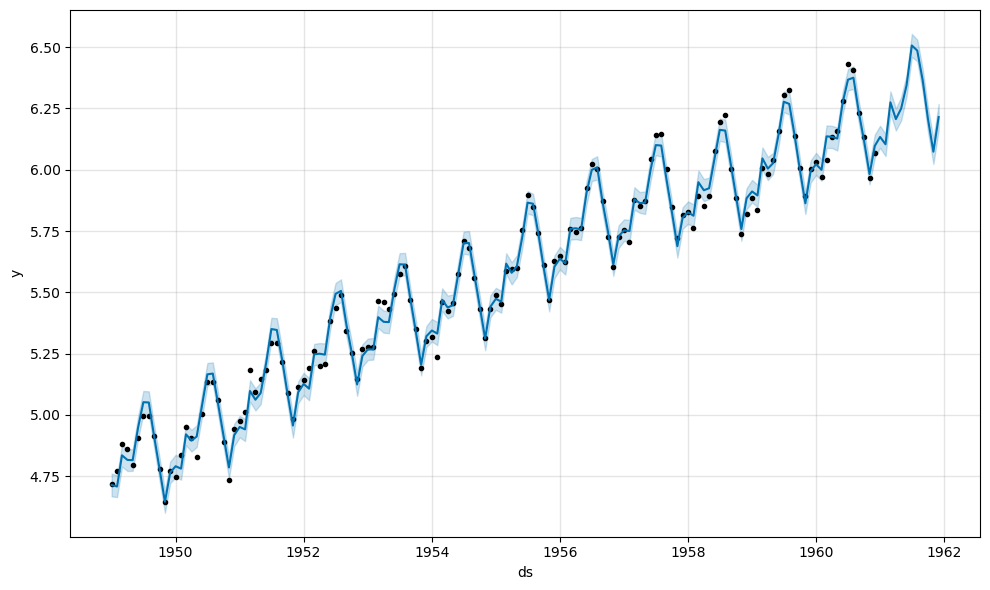

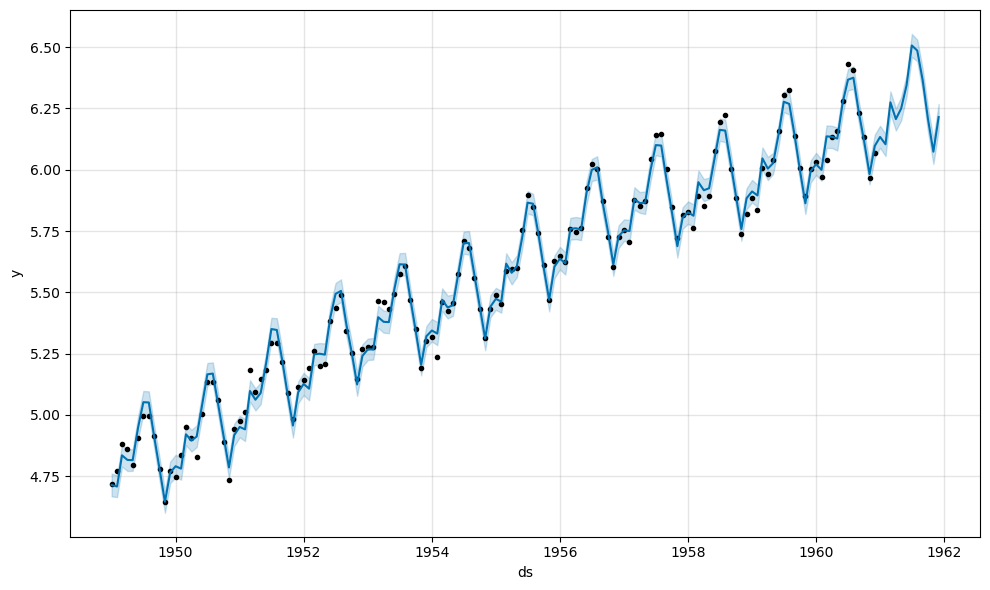

In [8]:
model.plot(forecast_data)

In [9]:
forecast_data['yhat']=np.exp(forecast_data['yhat'])
forecast_data['yhat_lower']=np.exp(forecast_data['yhat_lower'])
forecast_data['yhat_upper']=np.exp(forecast_data['yhat_upper'])

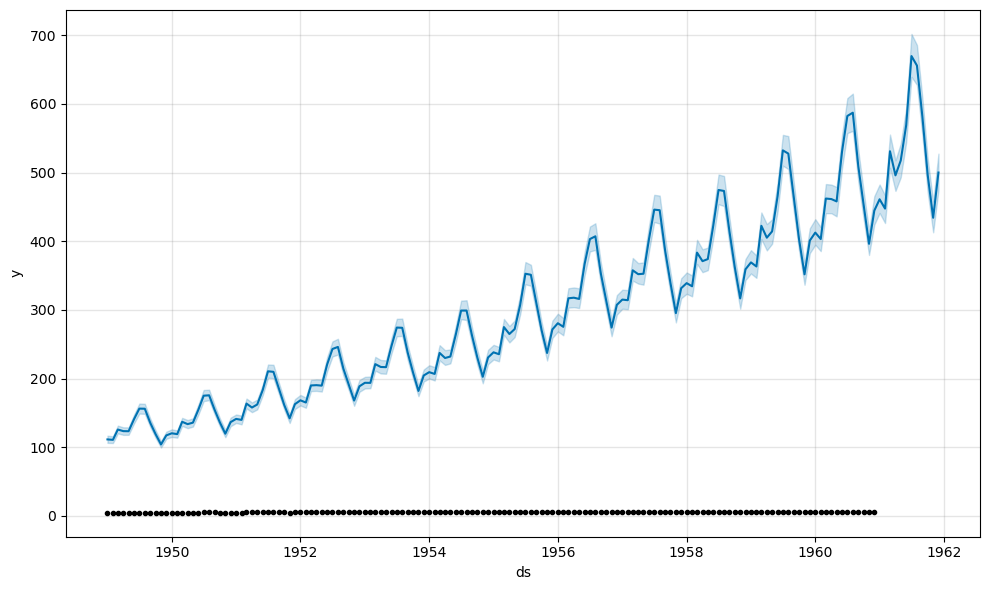

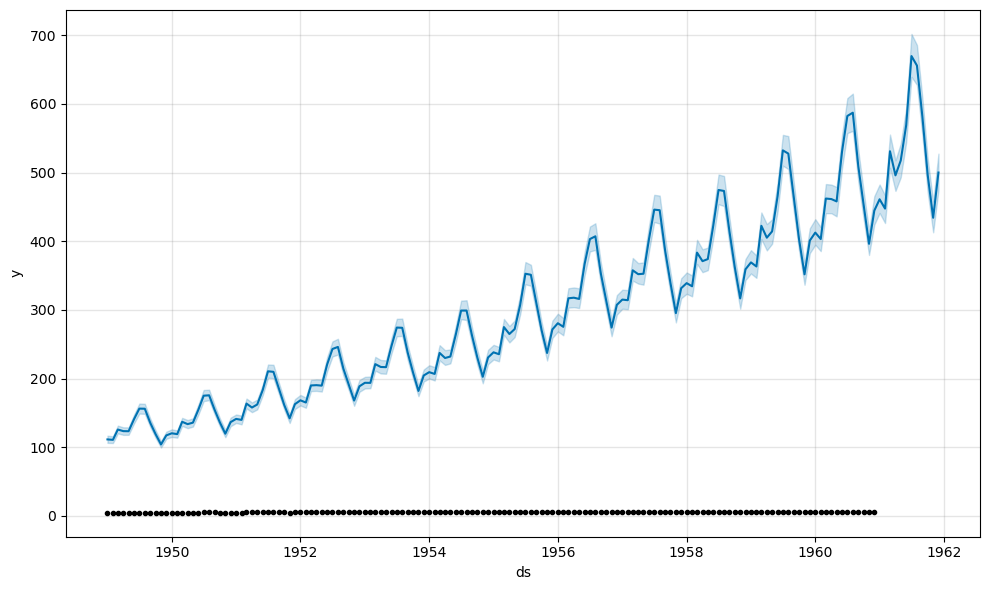

In [10]:
model.plot(forecast_data)